Single-feature baselines

Day 5. Tests the evaluation harness in `src/evaluate.py` and then scores every normalized feature on its own.
Only train (2020-2023) and validation (2024) rows with a 1-month label are used. Test rows are dropped right after loading.
Input: `model_table.csv`, `benchmark_ew.csv`. Outputs: `benchmark_nifty.csv`, `reports/single_feature_results.csv` and 4 charts in `reports/figures/`.

## Setup

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# src is one folder up from notebooks, so add that folder so the import works
sys.path.append("..")
from src.labels import make_forward_returns
from src.evaluate import rank_ic_by_date, ic_summary, bucket_returns, monotonicity
from src.evaluate import assign_buckets, top_k_returns, evaluate_score

MODEL_TABLE_PATH = "../data/processed/model_table.csv"
BENCHMARK_EW_PATH = "../data/processed/benchmark_ew.csv"
BENCHMARK_NIFTY_PATH = "../data/processed/benchmark_nifty.csv"
RESULTS_PATH = "../reports/single_feature_results.csv"
FIGURE_FOLDER = "../reports/figures/"

## 1. Load model table, keep only train + validation rows with a label

In [2]:
model_table = pd.read_csv(MODEL_TABLE_PATH, parse_dates=["Date"])

# drop test and warm-up rows right away, nothing below ever sees them
keep_rows = model_table["split"].isin(["train", "validation"]) & model_table["has_label_1m"]
train_val_df = model_table[keep_rows].copy()
train_val_df = train_val_df.reset_index(drop=True)

train_df = train_val_df[train_val_df["split"] == "train"].copy()
val_df = train_val_df[train_val_df["split"] == "validation"].copy()

print("splits present:", sorted(train_val_df["split"].unique()))
print("train rows:", len(train_df), "| months:", train_df["Date"].nunique(),
      "| from", train_df["Date"].min().date(), "to", train_df["Date"].max().date())
print("validation rows:", len(val_df), "| months:", val_df["Date"].nunique(),
      "| from", val_df["Date"].min().date(), "to", val_df["Date"].max().date())
print("latest date used anywhere below:", train_val_df["Date"].max().date())

splits present: ['train', 'validation']
train rows: 1440 | months: 48 | from 2020-01-31 to 2023-12-29
validation rows: 360 | months: 12 | from 2024-01-31 to 2024-12-31
latest date used anywhere below: 2024-12-31


## 2. Benchmarks: equal-weight and nifty 50

In [3]:
# equal-weight benchmark from day 2: mean fwd_1m of the 30 stocks on each date
benchmark_ew_table = pd.read_csv(BENCHMARK_EW_PATH, parse_dates=["Date"])
benchmark_ew = benchmark_ew_table.set_index("Date")["fwd_1m"]

print("equal-weight benchmark months:", len(benchmark_ew))
print(benchmark_ew.head(3))

equal-weight benchmark months: 92
Date
2019-01-31   -0.007079
2019-02-28    0.038374
2019-03-28    0.027002
Name: fwd_1m, dtype: float64


In [4]:
# try to download nifty 50 closes, if anything goes wrong just use equal-weight
benchmark_nifty = None
decision_dates = pd.DatetimeIndex(benchmark_ew_table["Date"])

try:
    import yfinance as yf

    start_date = decision_dates.min() - pd.Timedelta(days=10)
    end_date = decision_dates.max() + pd.Timedelta(days=5)
    nifty_download = yf.download("^NSEI", start=start_date, end=end_date, progress=False, auto_adjust=False)

    nifty_close = nifty_download["Close"]
    # newer yfinance returns a one-column table, turn it into a series
    if isinstance(nifty_close, pd.DataFrame):
        nifty_close = nifty_close.iloc[:, 0]
    nifty_close = nifty_close.dropna()

    if len(nifty_close) == 0:
        raise ValueError("download returned no rows")

    # close on each decision date (if a date is missing, use the last close before it)
    exact_matches = decision_dates.isin(nifty_close.index).sum()
    nifty_month_end = nifty_close.reindex(decision_dates, method="ffill")
    nifty_month_end_table = pd.DataFrame({"NIFTY50": nifty_month_end})

    # same forward-return function as the labels (the only place a negative shift is allowed)
    nifty_forward = make_forward_returns(nifty_month_end_table, 1)
    benchmark_nifty = nifty_forward["NIFTY50"]
    benchmark_nifty.name = "fwd_1m"

    nifty_to_save = benchmark_nifty.reset_index()
    nifty_to_save.columns = ["Date", "fwd_1m"]
    nifty_to_save.to_csv(BENCHMARK_NIFTY_PATH, index=False)

    print("nifty download ok, decision dates found exactly:", exact_matches, "out of", len(decision_dates))
    print("saved", BENCHMARK_NIFTY_PATH)
    print(benchmark_nifty.head(3))
except Exception as error:
    print("WARNING: could not download nifty 50 data:", error)

    # use the file from an earlier successful download if there is one
    try:
        saved_nifty = pd.read_csv(BENCHMARK_NIFTY_PATH, parse_dates=["Date"])
        benchmark_nifty = saved_nifty.set_index("Date")["fwd_1m"]
        print("using the saved file instead:", BENCHMARK_NIFTY_PATH)
    except Exception:
        print("WARNING: no saved nifty file either, using equal-weight benchmark only")

using the saved file instead: ../data/processed/benchmark_nifty.csv


## Part B: harness sanity checks

In [5]:
check_results = {}

def report_check(name, passed):
    check_results[name] = passed
    if passed:
        print("PASS:", name)
    else:
        print("FAIL:", name)

In [6]:
# check 1: if the score is the label itself, the ranking is perfect
perfect_df = train_val_df.copy()
perfect_df["perfect_score"] = perfect_df["fwd_1m"]

perfect_ic = rank_ic_by_date(perfect_df, "perfect_score")
perfect_by_date, perfect_buckets = bucket_returns(perfect_df, "perfect_score")
perfect_monotonicity = monotonicity(perfect_buckets)

print("perfect score: mean ic =", perfect_ic.mean(), "| monotonicity =", perfect_monotonicity)
report_check("1. perfect score gives mean ic = 1.0 and monotonicity = 1.0",
             abs(perfect_ic.mean() - 1) < 1e-9 and abs(perfect_monotonicity - 1) < 1e-9)

perfect score: mean ic = 1.0 | monotonicity = 0.9999999999999999
PASS: 1. perfect score gives mean ic = 1.0 and monotonicity = 1.0


In [7]:
# check 2: a random score should have no skill (train only)
np.random.seed(42)
random_df = train_df.copy()
random_df["random_score"] = np.random.rand(len(random_df))

random_ic = rank_ic_by_date(random_df, "random_score")
print("random score on train: mean ic =", round(random_ic.mean(), 4), "over", len(random_ic), "months")
report_check("2. random score has mean ic with abs < 0.05 on train", abs(random_ic.mean()) < 0.05)

random score on train: mean ic = -0.0123 over 48 months
PASS: 2. random score has mean ic with abs < 0.05 on train


In [8]:
# check 3: the opposite of the label should give exactly -1
reversed_df = train_val_df.copy()
reversed_df["reversed_score"] = -reversed_df["fwd_1m"]

reversed_ic = rank_ic_by_date(reversed_df, "reversed_score")
print("reversed score: mean ic =", reversed_ic.mean())
report_check("3. reversed score gives mean ic = -1.0", abs(reversed_ic.mean() + 1) < 1e-9)

reversed score: mean ic = -1.0
PASS: 3. reversed score gives mean ic = -1.0


In [9]:
# check 4: every date has exactly 5 buckets with 6 stocks each
bucket_df = train_val_df.copy()
bucket_df["bucket"] = assign_buckets(bucket_df, "mom_12_1_n", 5)

stocks_per_bucket = bucket_df.groupby(["Date", "bucket"]).size()
buckets_per_date = bucket_df.groupby("Date")["bucket"].nunique()

print("bucket sizes found:", sorted(stocks_per_bucket.unique()))
print("buckets per date found:", sorted(buckets_per_date.unique()))
report_check("4. each date has exactly 5 buckets of 6 stocks",
             (stocks_per_bucket == 6).all() and (buckets_per_date == 5).all())

bucket sizes found: [np.int64(6)]
buckets per date found: [np.int64(5)]
PASS: 4. each date has exactly 5 buckets of 6 stocks


## Part C: single-feature baselines

In [10]:
# every normalized feature is its own score
all_columns = list(model_table.columns)
n_columns = [name for name in all_columns if name.endswith("_n")]
secrel_columns = [name for name in all_columns if name.endswith("_secrel")]
feature_columns = n_columns + secrel_columns

print("features to test:", len(feature_columns))
print(feature_columns)

features to test: 17
['mom_1m_n', 'mom_6_1_n', 'mom_12_1_n', 'chmom_n', 'retvol_21d_n', 'retvol_63d_n', 'maxret_21d_n', 'beta_252d_n', 'idiovol_252d_n', 'log_turnover_21d_n', 'turnover_cv_21d_n', 'abn_turnover_n', 'amihud_21d_n', 'mom_12_1_secrel', 'retvol_63d_secrel', 'abn_turnover_secrel', 'amihud_21d_secrel']


In [11]:
# run the full evaluation for every feature, train and validation separately
train_results = {}
val_results = {}

for feature in feature_columns:
    train_results[feature] = evaluate_score(train_df, feature, k_list=[5, 10],
                                            benchmark_ew=benchmark_ew, benchmark_nifty=benchmark_nifty)
    val_results[feature] = evaluate_score(val_df, feature, k_list=[5, 10],
                                          benchmark_ew=benchmark_ew, benchmark_nifty=benchmark_nifty)

print("evaluated", len(train_results), "features on train and", len(val_results), "on validation")
print("example (mom_12_1_n, train):")
print({key: round(value, 4) for key, value in train_results["mom_12_1_n"].items()})

evaluated 17 features on train and 17 on validation
example (mom_12_1_n, train):
{'mean_ic': np.float64(0.0004), 'std_ic': np.float64(0.3051), 'icir': np.float64(0.0014), 't_stat': np.float64(0.0095), 'pct_positive': np.float64(54.1667), 'n_months': 48, 'monotonicity': np.float64(-0.6), 'bucket_1': np.float64(0.0241), 'bucket_2': np.float64(0.0263), 'bucket_3': np.float64(0.0178), 'bucket_4': np.float64(0.022), 'bucket_5': np.float64(0.0179), 'long_short_mean': np.float64(-0.0062), 'long_short_sharpe': np.float64(-0.2669), 'top5_mean_return': np.float64(0.0196), 'top5_excess_ew': np.float64(-0.0021), 'top5_sharpe_ew': np.float64(-0.1637), 'top5_hit_rate_ew': np.float64(47.9167), 'top5_max_drawdown': np.float64(-0.2262), 'top5_excess_nifty': np.float64(0.0053), 'top5_sharpe_nifty': np.float64(0.3977), 'top5_hit_rate_nifty': np.float64(56.25), 'top5_turnover': np.float64(0.2553), 'top10_mean_return': np.float64(0.0192), 'top10_excess_ew': np.float64(-0.0024), 'top10_sharpe_ew': np.float6

In [12]:
# robustness: rank ic against the 3-month forward return
# a 3-month label reaches 3 months past its date, so drop the last 3 dates of each split (embargo)
def drop_last_dates(df, n_dates):
    sorted_dates = sorted(df["Date"].unique())
    dates_to_keep = sorted_dates[:-n_dates]
    return df[df["Date"].isin(dates_to_keep)]

train_3m_df = drop_last_dates(train_df, 3)
val_3m_df = drop_last_dates(val_df, 3)

print("3m robustness: train months", train_3m_df["Date"].nunique(), "(last", train_3m_df["Date"].max().date(), ")")
print("3m robustness: validation months", val_3m_df["Date"].nunique(), "(last", val_3m_df["Date"].max().date(), ")")

train_ic_3m = {}
val_ic_3m = {}
for feature in feature_columns:
    train_ic_3m[feature] = rank_ic_by_date(train_3m_df, feature, "fwd_3m").mean()
    val_ic_3m[feature] = rank_ic_by_date(val_3m_df, feature, "fwd_3m").mean()

3m robustness: train months 45 (last 2023-09-29 )
3m robustness: validation months 9 (last 2024-09-30 )


In [13]:
# expected direction from the literature (0 = no strong prior)
expected_direction = {
    "mom_1m": -1, "mom_6_1": 1, "mom_12_1": 1, "chmom": 0,
    "retvol_21d": -1, "retvol_63d": -1, "maxret_21d": -1,
    "beta_252d": 0, "idiovol_252d": -1,
    "log_turnover_21d": 0, "turnover_cv_21d": 0, "abn_turnover": 0, "amihud_21d": 0,
}

# the _secrel versions use the direction of the feature they came from
def get_base_name(feature):
    if feature.endswith("_secrel"):
        return feature[:-len("_secrel")]
    return feature[:-len("_n")]

rows = []
for feature in feature_columns:
    train_stats = train_results[feature]
    val_stats = val_results[feature]

    expected_sign = expected_direction[get_base_name(feature)]
    train_sign = np.sign(train_stats["mean_ic"])
    val_sign = np.sign(val_stats["mean_ic"])

    if expected_sign == 0:
        agrees = "no prior"
    elif train_sign == expected_sign:
        agrees = "yes"
    else:
        agrees = "no"

    row = {
        "feature": feature,
        "train_mean_ic": train_stats["mean_ic"],
        "train_icir": train_stats["icir"],
        "train_tstat": train_stats["t_stat"],
        "train_pct_positive": train_stats["pct_positive"],
        "val_mean_ic": val_stats["mean_ic"],
        "val_icir": val_stats["icir"],
        "train_monotonicity": train_stats["monotonicity"],
        "train_top5_excess_ew": train_stats["top5_excess_ew"],
        "top5_turnover": train_stats["top5_turnover"],
        "train_ic_3m": train_ic_3m[feature],
        "val_ic_3m": val_ic_3m[feature],
        "expected_sign": expected_sign,
        "agrees_with_literature": agrees,
        "sign_flip": bool(train_sign * val_sign < 0),
    }
    rows.append(row)

results_table = pd.DataFrame(rows)
results_table = results_table.sort_values("train_icir", ascending=False).reset_index(drop=True)
results_table.to_csv(RESULTS_PATH, index=False)

print("saved", RESULTS_PATH)
print()
print(results_table.round(3).to_string())

saved ../reports/single_feature_results.csv

                feature  train_mean_ic  train_icir  train_tstat  train_pct_positive  val_mean_ic  val_icir  train_monotonicity  train_top5_excess_ew  top5_turnover  train_ic_3m  val_ic_3m  expected_sign agrees_with_literature  sign_flip
0        idiovol_252d_n          0.034       0.141        0.979              54.167        0.005     0.028                 0.9                 0.012          0.047        0.082      0.081             -1                     no      False
1          amihud_21d_n          0.020       0.110        0.764              60.417       -0.002    -0.012                 0.3                 0.007          0.285        0.059      0.078              0               no prior       True
2          retvol_63d_n          0.029       0.102        0.705              60.417       -0.082    -0.328                 0.7                 0.007          0.264        0.063     -0.042             -1                     no       True
3   abn

## Charts

In [14]:
# colors: blue, orange, aqua (first three slots of the validated palette), grey for reference lines
BLUE = "#2a78d6"
ORANGE = "#eb6834"
AQUA = "#1baf7a"
GREY = "#8a8a86"

def style_axes(ax):
    # light grid, no top/right box
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(True, color="#e3e2de", linewidth=0.6)
    ax.set_axisbelow(True)

print("chart colors ready")

chart colors ready


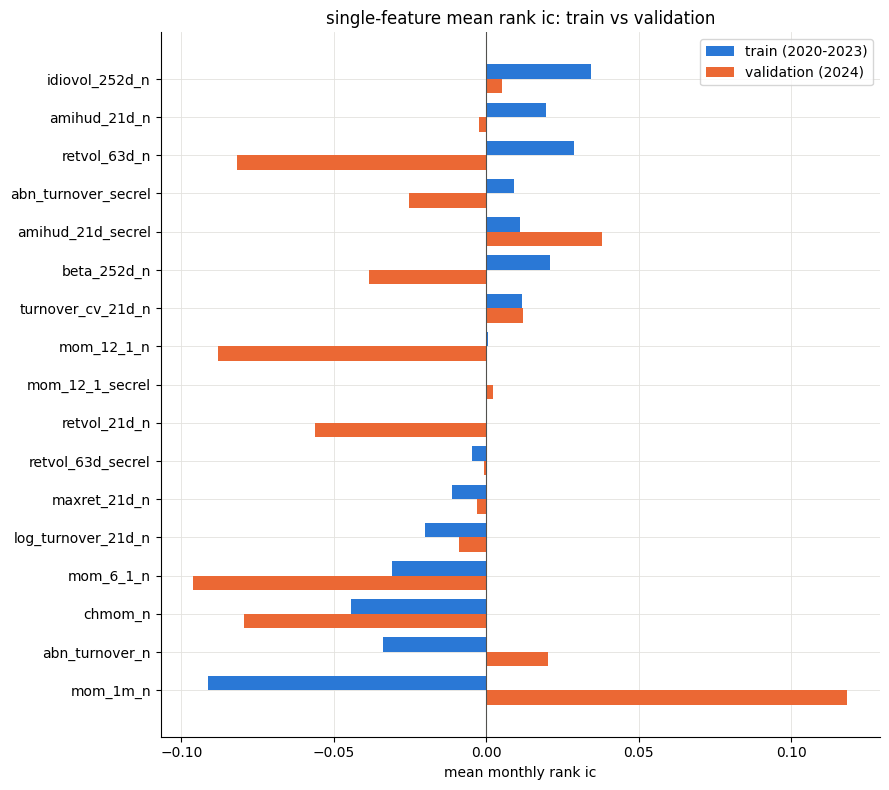

In [15]:
# chart 1: mean ic per feature, train vs validation
plot_table = results_table.iloc[::-1]
positions = np.arange(len(plot_table))
bar_height = 0.38

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(positions + bar_height / 2, plot_table["train_mean_ic"], height=bar_height, color=BLUE, label="train (2020-2023)")
ax.barh(positions - bar_height / 2, plot_table["val_mean_ic"], height=bar_height, color=ORANGE, label="validation (2024)")
ax.axvline(0, color="#52514e", linewidth=0.8)
ax.set_yticks(positions)
ax.set_yticklabels(plot_table["feature"])
ax.set_xlabel("mean monthly rank ic")
ax.set_title("single-feature mean rank ic: train vs validation")
ax.legend(loc="upper right")
style_axes(ax)
plt.tight_layout()
plt.savefig(FIGURE_FOLDER + "01_mean_ic_train_vs_val.png", dpi=150)
plt.show()

top 3 by abs train icir: ['mom_1m_n', 'abn_turnover_n', 'chmom_n']


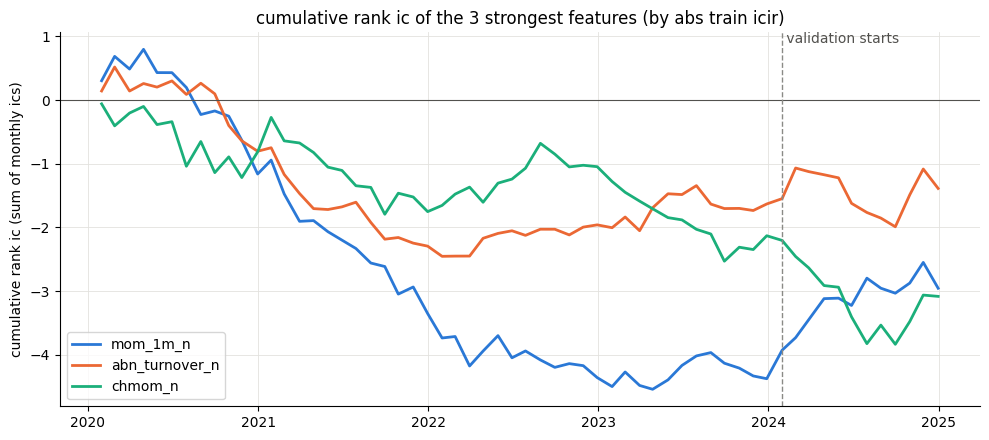

In [16]:
# chart 2: cumulative ic over time for the 3 features with the highest abs train icir
abs_icir = results_table["train_icir"].abs()
top3_features = list(results_table.loc[abs_icir.sort_values(ascending=False).index[:3], "feature"])
print("top 3 by abs train icir:", top3_features)

line_colors = [BLUE, ORANGE, AQUA]
validation_start = val_df["Date"].min()

fig, ax = plt.subplots(figsize=(10, 4.5))
for i in range(len(top3_features)):
    feature = top3_features[i]
    monthly_ic = rank_ic_by_date(train_val_df, feature)
    ax.plot(monthly_ic.index, monthly_ic.cumsum(), color=line_colors[i], linewidth=2, label=feature)

ax.axhline(0, color="#52514e", linewidth=0.8)
ax.axvline(validation_start, color=GREY, linestyle="--", linewidth=1)
ax.text(validation_start, ax.get_ylim()[1], " validation starts", va="top", color="#52514e")
ax.set_ylabel("cumulative rank ic (sum of monthly ics)")
ax.set_title("cumulative rank ic of the 3 strongest features (by abs train icir)")
ax.legend(loc="lower left")
style_axes(ax)
plt.tight_layout()
plt.savefig(FIGURE_FOLDER + "02_cumulative_ic_top3.png", dpi=150)
plt.show()

best feature on train: idiovol_252d_n | train icir: 0.141


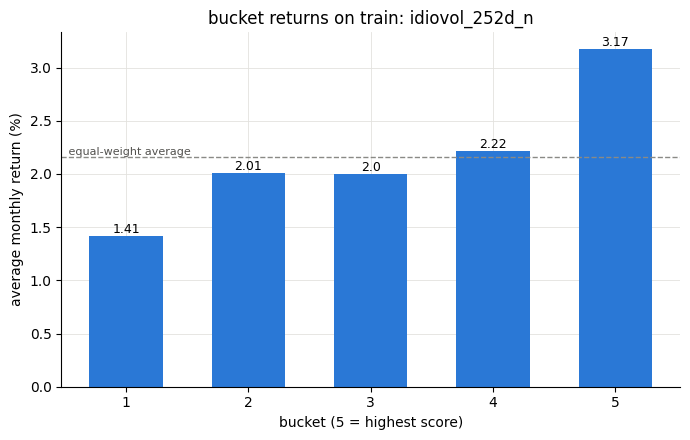

In [17]:
# the best feature = highest train icir (positive, so a long-only top-k can use it without flipping the sign)
best_feature = results_table.loc[0, "feature"]
print("best feature on train:", best_feature, "| train icir:", round(results_table.loc[0, "train_icir"], 3))

# chart 3: average return of buckets 1-5 on train
best_by_date, best_bucket_means = bucket_returns(train_df, best_feature)

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(best_bucket_means.index, best_bucket_means.values * 100, color=BLUE, width=0.6)
ew_average = benchmark_ew.loc[train_df["Date"].unique()].mean() * 100
ax.axhline(ew_average, color=GREY, linestyle="--", linewidth=1)
ax.text(0.5, ew_average, " equal-weight average", va="bottom", ha="left", color="#52514e", fontsize=8)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), round(bar.get_height(), 2),
            ha="center", va="bottom", fontsize=9)
ax.set_xlabel("bucket (5 = highest score)")
ax.set_ylabel("average monthly return (%)")
ax.set_title("bucket returns on train: " + best_feature)
style_axes(ax)
plt.tight_layout()
plt.savefig(FIGURE_FOLDER + "03_bucket_returns_best_feature.png", dpi=150)
plt.show()

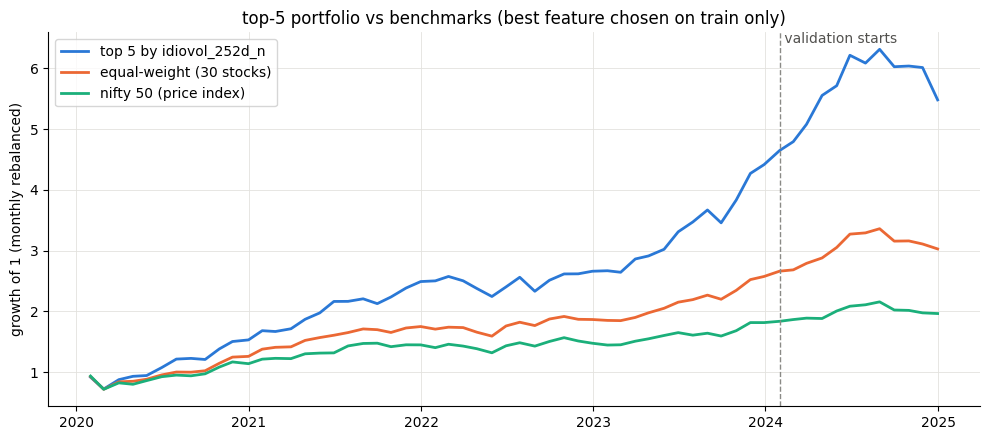

final growth of 1 -> top 5: 5.482 | equal-weight: 3.029


In [18]:
# chart 4: top-5 portfolio of the best feature vs benchmarks, train + validation
top5_returns = top_k_returns(train_val_df, best_feature, 5)
curve_dates = top5_returns.index

top5_curve = (1 + top5_returns).cumprod()
ew_curve = (1 + benchmark_ew.loc[curve_dates]).cumprod()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(curve_dates, top5_curve, color=BLUE, linewidth=2, label="top 5 by " + best_feature)
ax.plot(curve_dates, ew_curve, color=ORANGE, linewidth=2, label="equal-weight (30 stocks)")
if benchmark_nifty is not None:
    nifty_curve = (1 + benchmark_nifty.loc[curve_dates]).cumprod()
    ax.plot(curve_dates, nifty_curve, color=AQUA, linewidth=2, label="nifty 50 (price index)")

ax.axvline(validation_start, color=GREY, linestyle="--", linewidth=1)
ax.text(validation_start, ax.get_ylim()[1], " validation starts", va="top", color="#52514e")
ax.set_ylabel("growth of 1 (monthly rebalanced)")
ax.set_title("top-5 portfolio vs benchmarks (best feature chosen on train only)")
ax.legend(loc="upper left")
style_axes(ax)
plt.tight_layout()
plt.savefig(FIGURE_FOLDER + "04_top5_cumulative_vs_benchmarks.png", dpi=150)
plt.show()

print("final growth of 1 -> top 5:", round(top5_curve.iloc[-1], 3), "| equal-weight:", round(ew_curve.iloc[-1], 3))

## Summary

In [19]:
print("SANITY CHECKS")
for name in check_results:
    if check_results[name]:
        print("PASS:", name)
    else:
        print("FAIL:", name)
print("all sanity checks passed:", all(check_results.values()))
print()

print("TOP 5 FEATURES BY TRAIN ICIR (highest first)")
print(results_table[["feature", "train_mean_ic", "train_icir", "val_mean_ic", "val_icir"]].head(5).round(3).to_string(index=False))
print()

print("TOP 5 FEATURES BY ABS TRAIN ICIR (a strongly negative feature is just as useful, the model learns the sign)")
abs_order = results_table["train_icir"].abs().sort_values(ascending=False).index[:5]
print(results_table.loc[abs_order, ["feature", "train_mean_ic", "train_icir", "val_mean_ic", "val_icir"]].round(3).to_string(index=False))
print()

print("FEATURES WHOSE IC SIGN FLIPS BETWEEN TRAIN AND VALIDATION")
flipped = results_table[results_table["sign_flip"]]
print(flipped[["feature", "train_mean_ic", "val_mean_ic"]].round(3).to_string(index=False))
print()

print("FEATURES THAT DISAGREE WITH THE LITERATURE (train ic sign)")
disagree = results_table[results_table["agrees_with_literature"] == "no"]
print(disagree[["feature", "expected_sign", "train_mean_ic", "val_mean_ic"]].round(3).to_string(index=False))
print()

print("nifty benchmark available:", benchmark_nifty is not None)

SANITY CHECKS
PASS: 1. perfect score gives mean ic = 1.0 and monotonicity = 1.0
PASS: 2. random score has mean ic with abs < 0.05 on train
PASS: 3. reversed score gives mean ic = -1.0
PASS: 4. each date has exactly 5 buckets of 6 stocks
all sanity checks passed: True

TOP 5 FEATURES BY TRAIN ICIR (highest first)
            feature  train_mean_ic  train_icir  val_mean_ic  val_icir
     idiovol_252d_n          0.034       0.141        0.005     0.028
       amihud_21d_n          0.020       0.110       -0.002    -0.012
       retvol_63d_n          0.029       0.102       -0.082    -0.328
abn_turnover_secrel          0.009       0.068       -0.025    -0.220
  amihud_21d_secrel          0.011       0.068        0.038     0.223

TOP 5 FEATURES BY ABS TRAIN ICIR (a strongly negative feature is just as useful, the model learns the sign)
       feature  train_mean_ic  train_icir  val_mean_ic  val_icir
      mom_1m_n         -0.091      -0.378        0.118     0.443
abn_turnover_n         -0.0